# **Importing Data From Kaggle**

In [1]:
from google.colab import files
uploaded = files.upload()

Saving kaggle .json to kaggle .json


In [2]:
!ls /content

'kaggle .json'	 sample_data


In [3]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)

!mv kaggle.json /root/.kaggle/


!chmod 600 /root/.kaggle/kaggle.json

mv: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory


In [4]:
!kaggle datasets download -d omkargurav/face-mask-dataset

Dataset URL: https://www.kaggle.com/datasets/omkargurav/face-mask-dataset
License(s): unknown
100% 163M/163M [00:01<00:00, 154MB/s]



# **Unzip Dataset**

In [5]:
import zipfile

with zipfile.ZipFile('/content/face-mask-dataset.zip', 'r') as zip_ref:
    zip_ref.extractall('dataset')

# **Extracting path to Folders**

In [6]:
import os

dataset_path = "/content/dataset/data"  # apna extracted folder name

for folder in os.listdir(dataset_path):
    print(folder, ":", len(os.listdir(os.path.join(dataset_path, folder))))

without_mask : 3828
with_mask : 3725


# **Preprocessing**

In [7]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
dataset_path = "/content/dataset/data"

img_size = 224
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,          # ✔ Normalize
    validation_split=0.2     # ✔ Split data
)
train_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(img_size, img_size),  # ✔ Resize
    batch_size=batch_size,             # ✔ Batch
    class_mode='binary',               # ✔ Label
    subset='training'
)
val_data = datagen.flow_from_directory(
    dataset_path,
    target_size=(img_size, img_size),
    batch_size=batch_size,
    class_mode='binary',
    subset='validation'
)

Found 6043 images belonging to 2 classes.
Found 1510 images belonging to 2 classes.


In [8]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout

# **Defining BaseModel "MobileNetV2"**

In [9]:
base_model = MobileNetV2(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False  # freeze pretrained layers

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [10]:
model = Sequential()

model.add(base_model)
model.add(Flatten())

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))

model.add(Dense(1, activation='sigmoid'))

# **Compile**

In [11]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# **Training**

In [12]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=10
)

Epoch 1/10
116/189 ━━━━━━━━━━━━━━━━━━━━ 13s 182ms/step - accuracy: 0.9163 - loss: 1.1757

/usr/local/lib/python3.12/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(


189/189 ━━━━━━━━━━━━━━━━━━━━ 63s 234ms/step - accuracy: 0.9652 - loss: 0.4484 - val_accuracy: 0.9795 - val_loss: 0.1055
Epoch 2/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.9886 - loss: 0.0591 - val_accuracy: 0.9887 - val_loss: 0.0447
Epoch 3/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.9914 - loss: 0.0299 - val_accuracy: 0.9841 - val_loss: 0.0802
Epoch 4/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 15s 78ms/step - accuracy: 0.9927 - loss: 0.0438 - val_accuracy: 0.9874 - val_loss: 0.0759
Epoch 5/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 18s 95ms/step - accuracy: 0.9932 - loss: 0.0296 - val_accuracy: 0.9907 - val_loss: 0.0583
Epoch 6/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - accuracy: 0.9916 - loss: 0.0390 - val_accuracy: 0.9808 - val_loss: 0.2223
Epoch 7/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - accuracy: 0.9921 - loss: 0.0404 - val_accuracy: 0.9841 - val_loss: 0.1338
Epoch 8/10
189/189 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.9969 - loss: 0.0228 - val_accura

# Evaluation of Model
---



In [13]:
model.evaluate(val_data)

48/48 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.9921 - loss: 0.0367


[0.03666422888636589, 0.9920529723167419]

# **Accuracy Graph**

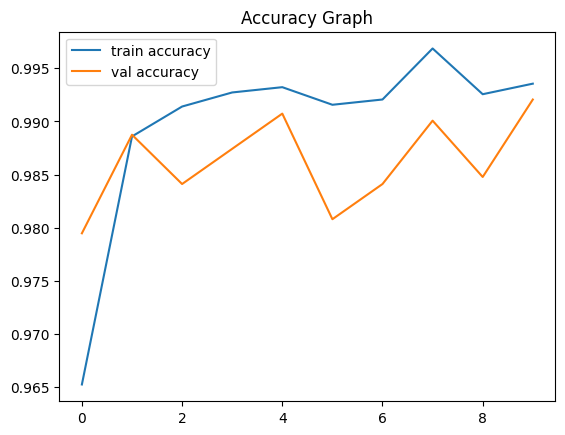

In [14]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train accuracy')
plt.plot(history.history['val_accuracy'], label='val accuracy')
plt.legend()
plt.title("Accuracy Graph")
plt.show()

# **Loss Graph**

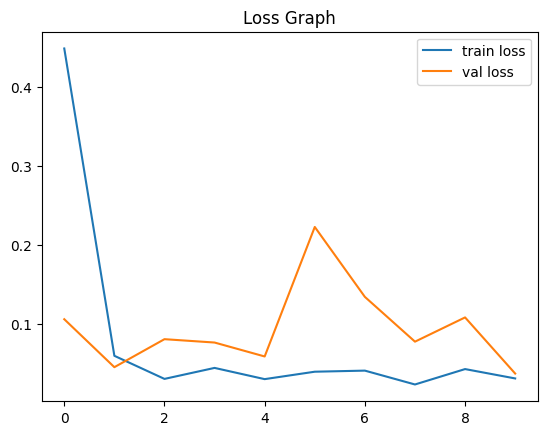

In [15]:
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title("Loss Graph")
plt.show()

# Save Model

In [33]:
model.save("mask_detector.keras")
print("Model saved successfully ✔")

Model saved successfully ✔


# **Load model for prediction**

In [34]:
import cv2
import numpy as np

def predict_image(img_path):
    img = cv2.imread(img_path)
    img = cv2.resize(img, (224,224))
    img = img / 255.0
    img = np.expand_dims(img, axis=0)

    pred = model.predict(img)[0][0]

    if pred > 0.5:
        return "NO MASK"
    else:
        return "MASK"

# **Single image Dectection**

In [19]:
result = predict_image("/content/dataset/data/without_mask/without_mask_1.jpg")
print(result)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
NO MASK


# **Multi Image Detection**

In [35]:
folder_path = "/content/dataset/data/with_mask"  # ya without_mask

for img_name in os.listdir(folder_path)[:10]:  # first 10 images
    img_path = os.path.join(folder_path, img_name)

    result = predict_image(img_path)

    print(img_name, "→", result)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
with_mask_3003.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
with_mask_3588.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
with_mask_1550.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
with_mask_3248.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
with_mask_2444.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
with_mask_1995.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
with_mask_58.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step
with_mask_2087.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
with_mask_1152.jpg → MASK
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
with_mask_1470.jpg → MASK


# Real image Detection with mask

In [36]:
from google.colab import files

uploaded = files.upload()

Saving Camo Print Sun Protection Face & Neck Gaiter.jpg to Camo Print Sun Protection Face & Neck Gaiter (1).jpg


Processing: Camo Print Sun Protection Face & Neck Gaiter (1).jpg
Faces: 3
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step


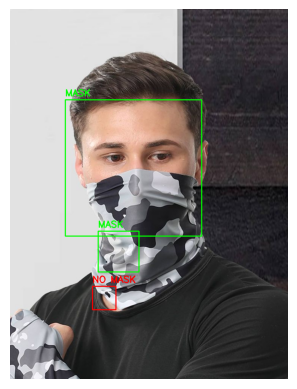

In [37]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Load the Haar Cascade classifier for face detection
face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

for img_name in uploaded.keys():

    print("Processing:", img_name)

    img_path = img_name

    img = cv2.imread(img_path)
    output = img.copy()

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.03,
        minNeighbors=2,
        minSize=(20,20)
    )

    print("Faces:", len(faces))

    for (x,y,w,h) in faces:

        face = img[y:y+h, x:x+w]
        face = cv2.resize(face, (224,224))
        face = face / 255.0
        face = np.expand_dims(face, axis=0)

        pred = model.predict(face)[0][0]

        if pred > 0.5:
            label = "NO MASK"
            color = (0,0,255)
        else:
            label = "MASK"
            color = (0,255,0)

        cv2.rectangle(output, (x,y), (x+w,y+h), color, 2)
        cv2.putText(output, label, (x,y-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

    plt.figure()
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

# **Real image Detection without mask**

In [38]:
from google.colab import files

uploaded = files.upload()

Saving download.jpg to download (2).jpg


Processing: download (2).jpg
Faces: 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step


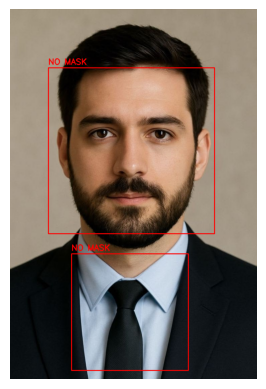

In [39]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

for img_name in uploaded.keys():

    print("Processing:", img_name)

    img_path = img_name

    img = cv2.imread(img_path)
    output = img.copy()

    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.03,
        minNeighbors=2,
        minSize=(20,20)
    )

    print("Faces:", len(faces))

    for (x,y,w,h) in faces:

        face = img[y:y+h, x:x+w]
        face = cv2.resize(face, (224,224))
        face = face / 255.0
        face = np.expand_dims(face, axis=0)

        pred = model.predict(face)[0][0]

        if pred > 0.5:
            label = "NO MASK"
            color = (0,0,255)
        else:
            label = "MASK"
            color = (0,255,0)

        cv2.rectangle(output, (x,y), (x+w,y+h), color, 2)
        cv2.putText(output, label, (x,y-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

    plt.figure()
    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

# **Camera Capture Function**

In [40]:
from IPython.display import Javascript
from google.colab.output import eval_js
import base64
import cv2
import numpy as np

def capture_image():
    js = Javascript('''
        async function capture() {
            const div = document.createElement('div');
            const video = document.createElement('video');
            const stream = await navigator.mediaDevices.getUserMedia({video: true});

            video.srcObject = stream;
            await video.play();

            await new Promise(resolve => setTimeout(resolve, 2000));

            const canvas = document.createElement('canvas');
            canvas.width = video.videoWidth;
            canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0);

            stream.getTracks().forEach(track => track.stop());

            return canvas.toDataURL('image/jpeg');
        }
        capture();
    ''')
    display(js)
    data = eval_js("capture()")

    binary = base64.b64decode(data.split(',')[1])
    np_arr = np.frombuffer(binary, np.uint8)
    img = cv2.imdecode(np_arr, cv2.IMREAD_COLOR)

    return img

# **Load Model + Face Cascade**

In [41]:
import tensorflow as tf
import os
import cv2 # Needed for face_cascade and other CV operations in the notebook

# Define the model filename
model_filename = "mask_detector.keras"

# Check if the model file exists. If not, save the currently trained model.
# The 'model' variable is available in the kernel from previous training steps.
if not os.path.exists(model_filename):
    print(f"Model file '{model_filename}' not found. Saving the trained model to '{model_filename}'.")
    # This assumes 'model' (the trained Keras model) is available in the global scope.
    model.save(model_filename)
else:
    print(f"Model file '{model_filename}' found. Loading existing model.")

# Load the model
model = tf.keras.models.load_model(model_filename)

# Load the face cascade classifier
face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)


Model file 'mask_detector.keras' found. Loading existing model.


# **Live Detection** **Function**

In [43]:
import matplotlib.pyplot as plt

def detect_live():

    frame = capture_image()
    output = frame.copy()

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.03,
        minNeighbors=2,
        minSize=(20,20)
    )

    print("Faces:", len(faces))

    for (x,y,w,h) in faces:

        face = frame[y:y+h, x:x+w]
        face = cv2.resize(face, (224,224))
        face = face / 255.0
        face = np.expand_dims(face, axis=0)

        pred = model.predict(face)[0][0]

        if pred > 0.5:
            label = "NO MASK"
            color = (0,0,255)
        else:
            label = "MASK"
            color = (0,255,0)

        cv2.rectangle(output, (x,y), (x+w,y+h), color, 2)
        cv2.putText(output, label, (x,y-10),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.8, color, 2)

    plt.imshow(cv2.cvtColor(output, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

# **Run Live Detection**

<IPython.core.display.Javascript object>

Faces: 2
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


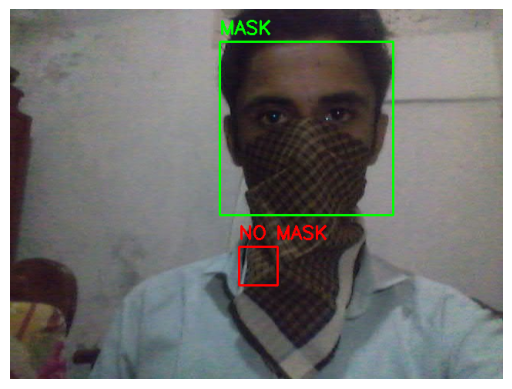

In [47]:
detect_live()